## Part 1 — Generate multivariate data with known group structure
We simulate **four groups** in an underlying two-dimensional space, mix them into **12 observed variables**, and add measurement noise. The group labels are retained only for **evaluation**, not for fitting PCA, the autoencoders, or K-means.

This resembles multivariate experimental measurements (e.g., correlated traits or metabolomic features) with an underlying low-dimensional structure.

X shape: (1000, 12) | group sizes: [250 250 250 250]
Max absolute feature mean after scaling: 0.0


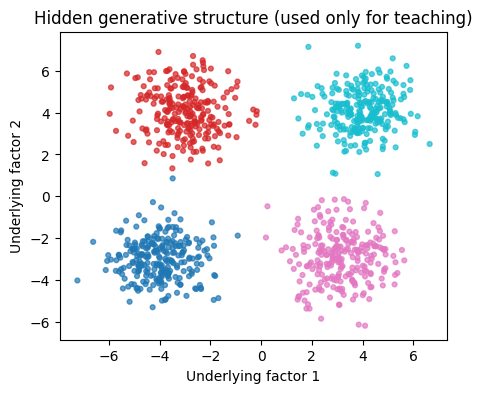

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, mean_squared_error
from scipy.linalg import subspace_angles

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)  # reasonable CPU usage in a classroom

n_samples, n_features, n_clusters, latent_dim = 1000, 12, 4, 2
z_true, true_group = make_blobs(
    n_samples=n_samples, centers=[(-4,-3), (-3,4), (3,-3), (4,4)],
    cluster_std=[1.0, 1.1, 1.1, 1.0], random_state=SEED
)
# Orthonormal mixing from 2 dimensions into 12 observed variables.
mix, _ = np.linalg.qr(rng.normal(size=(n_features, latent_dim)))
X_observed = z_true @ mix.T + rng.normal(scale=0.20, size=(n_samples, n_features))
X = StandardScaler().fit_transform(X_observed).astype('float32')
print('X shape:', X.shape, '| group sizes:', np.bincount(true_group))
print('Max absolute feature mean after scaling:', np.abs(X.mean(axis=0)).max().round(6))

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(z_true[:,0], z_true[:,1], c=true_group, s=12, cmap='tab10', alpha=.7)
ax.set(title='Hidden generative structure (used only for teaching)', xlabel='Underlying factor 1', ylabel='Underlying factor 2')
plt.show()

## Part 2 — PCA as rotation and projected “shadows” (interactive)

Imagine a light shining **perpendicular to a chosen axis**. Every observation casts a *shadow* onto that axis: its scalar projection. Rotating the axis changes both the spacing of the shadows and how well distinct groups appear separated.

For a centered 2D point $\mathbf{x}_i$, an axis at angle $\theta$ has unit direction $\mathbf{u}(\theta)=(\cos\theta,\sin\theta)$, and the shadow is

$$s_i(\theta)=\mathbf{x}_i^\top\mathbf{u}(\theta).$$

**PCA objective function is to maximize the variance of the shadows by changing the angle the light**, not the maximizing the best clustering.
### Reflection :
 - How does this achieve the clustering objective? Hint: Is there a hyperparameter to consider? Consider KNN as an example.

$$\theta_{\mathrm{PC1}}=\arg\max_{\theta}\operatorname{Var}[s(\theta)].$$

We use a separate **two-feature, two-group teaching dataset** where the high-variance direction is deliberately different from the best clustering direction. The group colors are known labels *for evaluation*, not information given to PCA or K-means.

Move the slider between **0° (horizontal shadows)** and **90° (vertical shadows)**. Compare shadow spread, K-means grouping, explained variance, and Adjusted Rand Index (ARI).

In [2]:
# Geometric demonstration: rotation, 1D projections ("shadows"), and grouping.
# Separate from the 12-variable dataset used by the rest of the lab.
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

rng_rotation = np.random.default_rng(2026)
n_per_group = 150
y_demo = np.repeat([0, 1], n_per_group)
# Large horizontal variation, but the two groups differ mostly vertically.
X_demo = np.column_stack([
    rng_rotation.normal(0, 2.5, 2 * n_per_group),
    (2 * y_demo - 1) * 0.8 + rng_rotation.normal(0, 0.22, 2 * n_per_group),
])
X_demo -= X_demo.mean(axis=0)
pca_demo = PCA(n_components=2).fit(X_demo)
angle_pc1 = np.degrees(np.arctan2(*pca_demo.components_[0, ::-1])) % 180

angles = np.arange(0, 181, 2)
variances, scores = [], []
for angle in angles:
    direction = np.array([np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))])
    shadows = X_demo @ direction
    variances.append(shadows.var(ddof=1))
    assignments = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(shadows.reshape(-1, 1))
    scores.append(adjusted_rand_score(y_demo, assignments))
variances, scores = np.array(variances), np.array(scores)
best_cluster_angle = angles[np.argmax(scores)]
print(f'PC1 angle: {angle_pc1:.1f}°; angle with highest K-means ARI: {best_cluster_angle:.1f}°')

# Plot on demand. Angle 0, 45, 90 are viewable without Jupyter widgets.
def show_rotation(angle=0):
    a = np.deg2rad(angle)
    direction = np.array([np.cos(a), np.sin(a)])
    normal = np.array([-np.sin(a), np.cos(a)])
    shadows = X_demo @ direction
    projected_points = np.outer(shadows, direction)
    assignments = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(shadows.reshape(-1,1))
    ari = adjusted_rand_score(y_demo, assignments)
    var = shadows.var(ddof=1)
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
    colors = np.where(y_demo == 0, 'tab:blue', 'tab:orange')
    ax = axs[0]
    ax.scatter(X_demo[:,0], X_demo[:,1], c=colors, s=12, alpha=0.40)
    # A subset of perpendicular "light rays" down to the selected axis.
    for i in range(0, len(X_demo), 12):
        ax.plot([X_demo[i,0], projected_points[i,0]],
                [X_demo[i,1], projected_points[i,1]], color='grey', alpha=.24, lw=.8)
    ax.scatter(projected_points[:,0], projected_points[:,1], c=colors, s=9, alpha=.55)
    span = 8
    ax.plot([-span*direction[0], span*direction[0]],
            [-span*direction[1], span*direction[1]], 'k-', lw=2, label='Projection axis')
    ax.set(xlabel='Feature 1', ylabel='Feature 2', title=f'Rotate axis: {angle}°')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(loc='upper right', fontsize=8)

    ax = axs[1]
    for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
        ax.hist(shadows[y_demo == label], bins=np.linspace(-9,9,36),
                alpha=.55, color=color, label=f'True group {label}', density=True)
    ax.set(xlabel='1D shadow coordinate', ylabel='Density',
           title=f'Projected variance={var:.2f} | K-means ARI={ari:.2f}')
    ax.legend(fontsize=8)

    ax = axs[2]
    ax.plot(angles, variances / variances.max(), label='Relative projected variance', lw=2)
    ax.plot(angles, scores, label='K-means ARI', lw=2)
    ax.axvline(angle_pc1, color='tab:green', ls='--', label='PCA PC1')
    ax.axvline(angle, color='grey', ls=':', label='Selected angle')
    ax.set(xlim=(0,180), ylim=(-.1,1.1), xlabel='Axis angle (degrees)',
           ylabel='Relative variance or ARI', title='PCA objective ≠ clustering objective')
    ax.legend(fontsize=8, loc='best')
    plt.show()

try:
    import ipywidgets as widgets
    from IPython.display import display
    display(widgets.interactive(show_rotation, angle=widgets.IntSlider(
        value=0, min=0, max=180, step=5, description='Rotation °', continuous_update=False)))
except ImportError:
    print('Optional: install ipywidgets for the interactive slider.')
    for angle in (0, 45, 90):
        show_rotation(angle)


PC1 angle: 0.4°; angle with highest K-means ARI: 90.0°


interactive(children=(IntSlider(value=0, continuous_update=False, description='Rotation °', max=180, step=5), …

### Discussion — When shadows become clusters

1. At which rotation do the projected shadows have **maximum variance**? Why does PCA select this direction?
2. At which rotation do **the two groups separate best**? Does it coincide with PC1?
3. Why can high reconstruction fidelity and strong group separation favor different directions?
4. If group labels were available during training, what **supervised** technique (e.g., linear discriminant analysis) could explicitly favor group separation?
5. **Extension:** Compare K-means ARI on 1D PC1 scores, 1D PC2 scores, and the full 2D space. A projection useful for clustering need not be a leading principal component.

**Terminology:** PCA rotates *coordinate axes* (equivalently, projects observations onto new directions). It does **not** rotate points to optimize grouping and does not use labels. Clustering shown here is a downstream evaluation.